# **Proyecto 1 - Etapa 2**

## **Importaciones**

In [31]:
import re
import unicodedata

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk import PorterStemmer
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')
nltk.download('wordnet')
stop_words = stopwords.words('spanish')
wpt = nltk.WordPunctTokenizer()
ps = PorterStemmer()
import re
import unicodedata
from collections import Counter

import nltk
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\juanc\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\juanc\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## **Entendimiento y Preparación de los Datos**

### **Entendimiento**

Se importan los datos.

In [32]:
original_data = pd.read_excel('data/Datos_proyecto.xlsx')

print("Dimensiones:", original_data.shape, "\n")

print("Tipos de datos por columna:")
print(original_data.dtypes)

display(original_data.head())

print("\nValores únicos por columna:")
print(original_data.nunique())

Dimensiones: (2424, 2) 

Tipos de datos por columna:
textos    object
labels     int64
dtype: object


,textos,labels
0,"""Aprendizaje"" y ""educación"" se consideran sinó...",4
1,Para los niños más pequeños (bebés y niños peq...,4
2,"Además, la formación de especialistas en medic...",3
3,En los países de la OCDE se tiende a pasar de ...,4
4,Este grupo se centró en las personas que padec...,3



Valores únicos por columna:
textos    2424
labels       3
dtype: int64


### **Perfilamiento de los Datos**

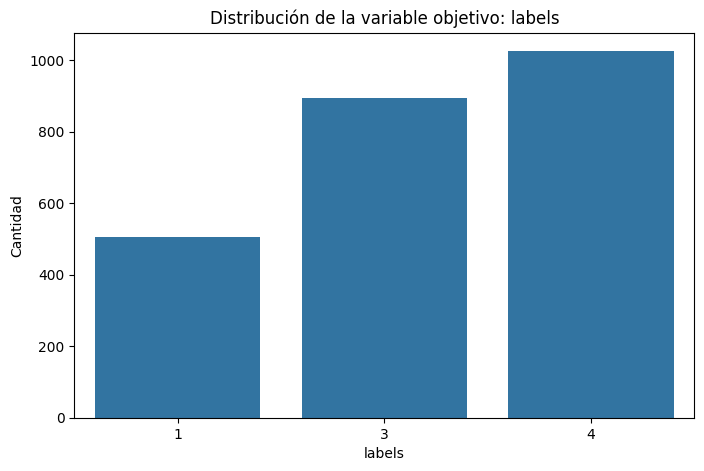

labels
4    1025
3     894
1     505
Name: count, dtype: int64


In [33]:
plt.figure(figsize=(8, 5))
sns.countplot(data=original_data, x='labels')
plt.title('Distribución de la variable objetivo: labels')
plt.ylabel('Cantidad')
plt.show()

label_counts = original_data['labels'].value_counts()
print(label_counts)

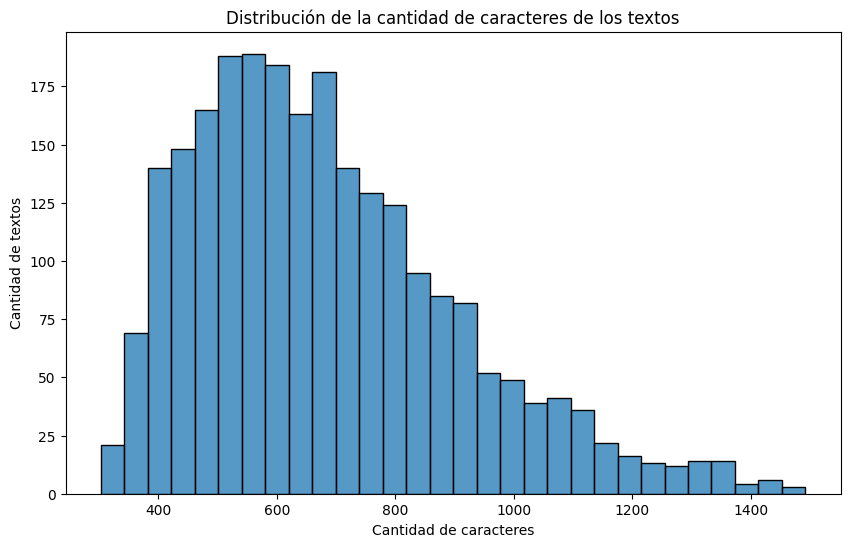

Estadísticas descriptivas de la cantidad de caracteres de los textos:
count    2424.000000
mean      683.223185
std       223.563695
min       303.000000
25%       513.000000
50%       647.000000
75%       809.250000
max      1492.000000
Name: textos, dtype: float64


In [34]:
text_character_counts = original_data['textos'].str.len()
plt.figure(figsize=(10, 6))
sns.histplot(text_character_counts, bins=30)
plt.title('Distribución de la cantidad de caracteres de los textos')
plt.xlabel('Cantidad de caracteres')
plt.ylabel('Cantidad de textos')
plt.show()

print("Estadísticas descriptivas de la cantidad de caracteres de los textos:")
print(text_character_counts.describe())

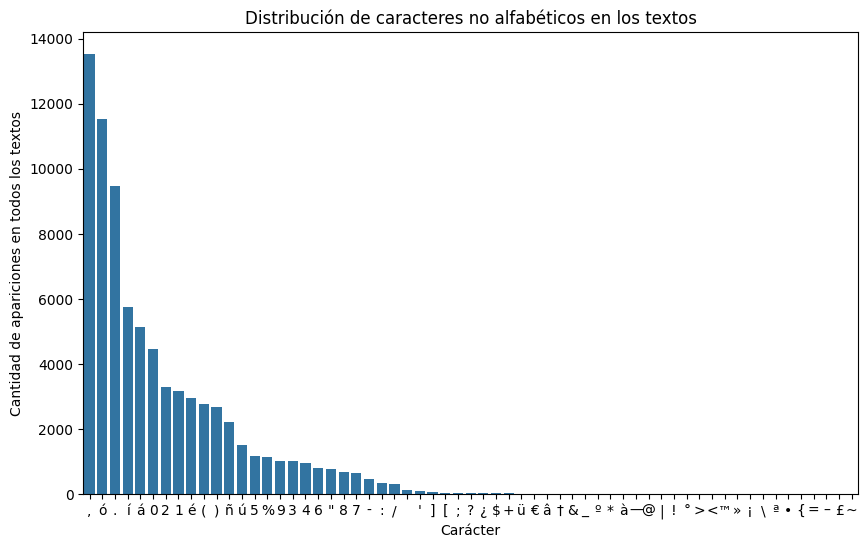

   character  count
3          ,  13523
1          ó  11536
2          .   9458
9          í   5750
4          á   5133
..       ...    ...
47         {      1
57         =      1
58         –      1
59         £      1
60         ~      1

[61 rows x 2 columns]
Estadísticas descriptivas de la cantidad de caracteres no alfabéticos:
count       61.000000
mean      1286.147541
std       2719.823572
min          1.000000
25%          4.000000
50%         35.000000
75%       1014.000000
max      13523.000000
Name: count, dtype: float64


In [35]:
text_non_alpha_chars = original_data['textos'].str.lower().str.findall(r'[^a-zA-Z\s]', flags=re.UNICODE)
all_non_alpha_chars = [char for sublist in text_non_alpha_chars for char in sublist]
non_alpha_char_counts = Counter(all_non_alpha_chars)

non_alpha_char_counts_df = pd.DataFrame(non_alpha_char_counts.items(), columns=['character', 'count']).sort_values(by='count', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=non_alpha_char_counts_df, x='character', y='count')
plt.title('Distribución de caracteres no alfabéticos en los textos')
plt.xlabel('Carácter')
plt.ylabel('Cantidad de apariciones en todos los textos')
plt.show()

print(non_alpha_char_counts_df)

print("Estadísticas descriptivas de la cantidad de caracteres no alfabéticos:")
print(non_alpha_char_counts_df['count'].describe())

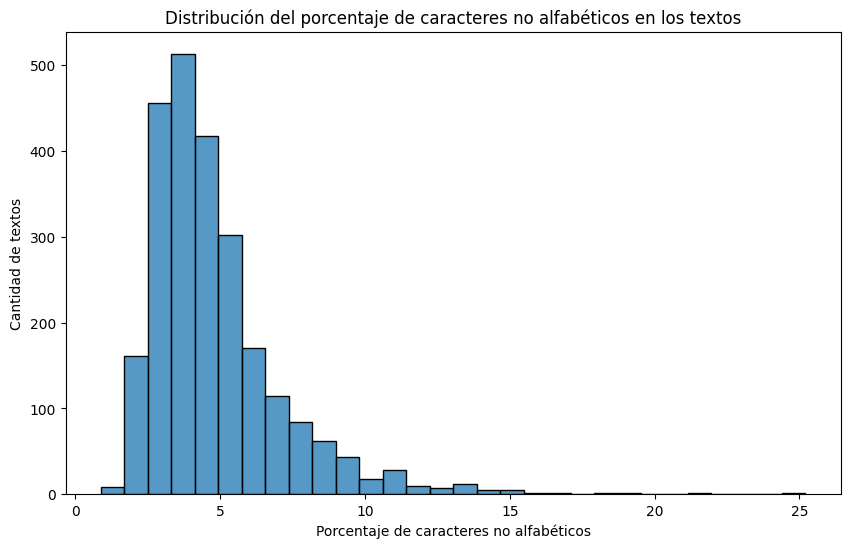

,special_char_percentage
631,25.208681
1695,21.644295
524,18.823529
546,18.701095
550,16.964286
254,15.588235
951,15.360502
1318,15.257048
2109,15.158371
721,15.025907


Estadísticas descriptivas del porcentaje de caracteres no alfabéticos por texto:
count    2424.000000
mean        4.800697
std         2.289457
min         0.878294
25%         3.276147
50%         4.240919
75%         5.604861
max        25.208681
Name: special_char_percentage, dtype: float64


In [36]:
special_char_percentages = [(len(na_chars)/total)*100 for na_chars, total in zip(text_non_alpha_chars, text_character_counts)]

special_char_percentages_df = pd.DataFrame({
    'special_char_percentage': special_char_percentages
})

plt.figure(figsize=(10, 6))
sns.histplot(special_char_percentages_df['special_char_percentage'], bins=30)
plt.title('Distribución del porcentaje de caracteres no alfabéticos en los textos')
plt.xlabel('Porcentaje de caracteres no alfabéticos')
plt.ylabel('Cantidad de textos')
plt.show()

special_char_percentages_df.sort_values(by='special_char_percentage', ascending=False, inplace=True)
display(special_char_percentages_df.head(15))

print("Estadísticas descriptivas del porcentaje de caracteres no alfabéticos por texto:")
print(special_char_percentages_df['special_char_percentage'].describe())

In [37]:
for index, row in special_char_percentages_df.head(15).iterrows():
    print(f"Texto {index}: {original_data['textos'].iloc[index]}\n")

Texto 631: Hijos de la austeridad: impacto de la gran recesión en la pobreza infantil en los países ricos, Oxford University Press, http://dx.doi.org/10.1093/oso/9780198797968.003.0012. ¡La Geografía de la I5 Intergeneracional! Uk/28401/l/Helping Patents to Parent report.pdf (consultado el 7 de agosto de 2018). Org/p/hdl/improv/1608.html (consultado el 11 de abril de 2018). Org/file:///C:/Users/thevenon o/Downloads/4448-157-5923-l-10-20180213.pdf. Handbook of labor Economics, 4A, https://economics.ubc.ca/files/2013/05/pdf paper nicole-fortin-decomposition-methods.pdf (consultado el 10 de abril de 2018).

Texto 1695: En 2016, las mayores tasas de incidencia de ITS se registraron en Bayankhongor (36,5 casos por 10.000), Domod (34,7), Sukhbaatar (31,5), Khuvsgul (26,5), Govi-Altai (24,0), Tuv (23,7), Govisumber (23,6) y Domogovi (21,3) Aimags y la ciudad de Ulán Bator (22,2). La morbilidad de la tricomoniasis es más elevada en los aimags de Domod (60,7), Bayankhongor (53,3), Bulgan (17,5)

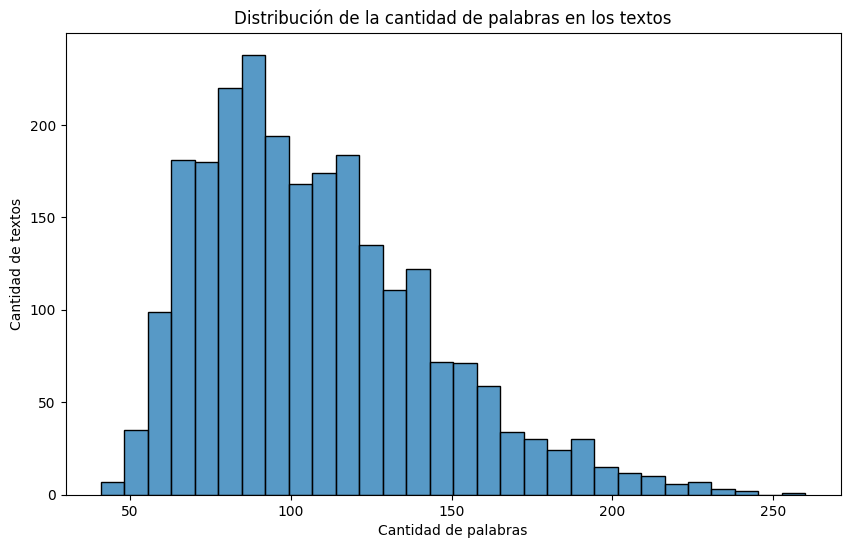

Estadísticas descriptivas de la cantidad de palabras en los textos:
count    2424.000000
mean      107.924092
std        35.575349
min        41.000000
25%        81.000000
50%       102.000000
75%       129.000000
max       260.000000
Name: textos, dtype: float64


In [38]:
text_word_counts = original_data['textos'].str.split().str.len()
plt.figure(figsize=(10, 6))
sns.histplot(text_word_counts, bins=30)
plt.title('Distribución de la cantidad de palabras en los textos')
plt.xlabel('Cantidad de palabras')
plt.ylabel('Cantidad de textos')
plt.show()

print("Estadísticas descriptivas de la cantidad de palabras en los textos:")
print(text_word_counts.describe())

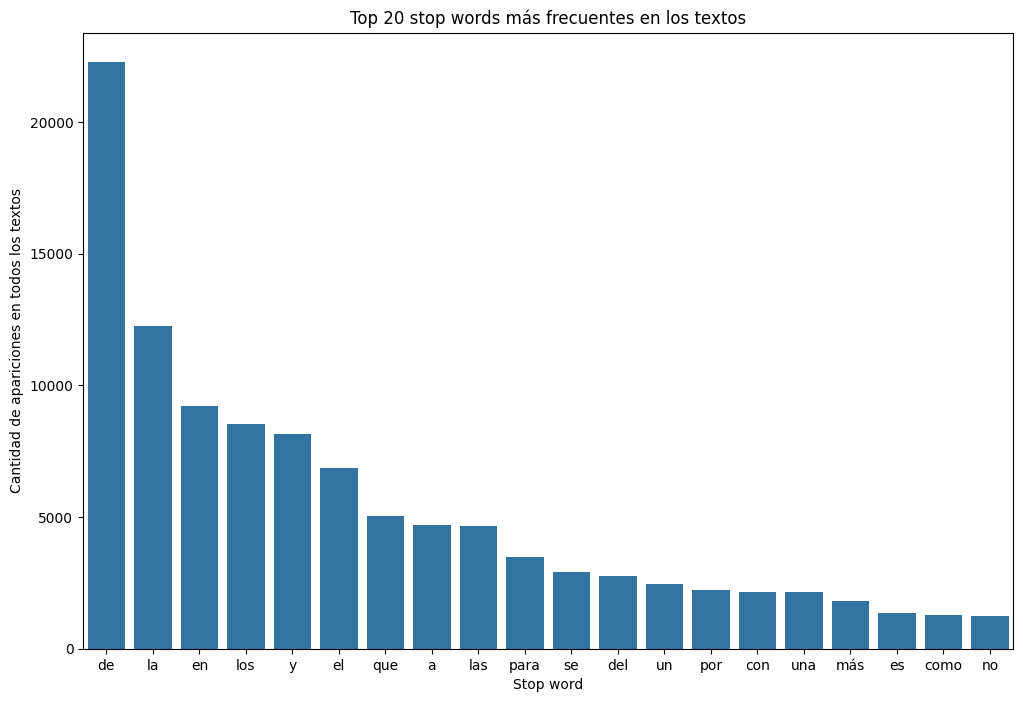

    stop_word  count
0          de  22277
1          la  12256
4          en   9218
7         los   8551
5           y   8137
..        ...    ...
276   tendrás      0
309    tenida      0
310   tenidos      0
311   tenidas      0
312     tened      0

[313 rows x 2 columns]
Estadísticas descriptivas de la cantidad de apariciones de stop words:
count      313.000000
mean       393.067093
std       1793.521058
min          0.000000
25%          0.000000
50%          1.000000
75%         50.000000
max      22277.000000
Name: count, dtype: float64


In [39]:
stop_word_counts = {word: original_data['textos'].str.count(rf'\b{re.escape(word)}\b', flags=re.IGNORECASE).sum() for word in stop_words}
stop_word_counts_df = pd.DataFrame(list(stop_word_counts.items()), columns=['stop_word', 'count']).sort_values(by='count', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(data=stop_word_counts_df.head(20), x='stop_word', y='count')
plt.title('Top 20 stop words más frecuentes en los textos')
plt.xlabel('Stop word')
plt.ylabel('Cantidad de apariciones en todos los textos')
plt.show()

print(stop_word_counts_df)

print("Estadísticas descriptivas de la cantidad de apariciones de stop words:")
print(stop_word_counts_df['count'].describe())

### **Análisis de Calidad de Datos**

#### **Completitud**

In [40]:
print("Valores nulos por columna:")
print(original_data.isnull().sum())

Valores nulos por columna:
textos    0
labels    0
dtype: int64


#### **Unicidad**

In [41]:
print("Cantidad de textos duplicados:")
print(original_data['textos'].duplicated().sum())

Cantidad de textos duplicados:
0


#### **Validez**

In [42]:
print("Conteo de valores de labels:")
print(original_data['labels'].value_counts())

Conteo de valores de labels:
labels
4    1025
3     894
1     505
Name: count, dtype: int64


In [43]:
original_data['textos'] = original_data['textos'].astype('string')

In [44]:
print("Tipos de datos por columna:")
print(original_data.dtypes)

Tipos de datos por columna:
textos    string[python]
labels             int64
dtype: object


### **Preparación**

In [45]:
nltk.download('punkt')
nltk.download('punkt_tab')

# Funciones de reemplazo
def replace_accents(text: str) -> str:
    normalized = unicodedata.normalize('NFD', text)
    without_accents = ''.join(c for c in normalized if unicodedata.category(c) != 'Mn')
    return without_accents

def replace_numbers_with_text(text: str) -> str:
    num_map = {
        '0': 'cero',
        '1': 'uno',
        '2': 'dos',
        '3': 'tres',
        '4': 'cuatro',
        '5': 'cinco',
        '6': 'seis',
        '7': 'siete',
        '8': 'ocho',
        '9': 'nueve'
    }
    return re.sub(r'\d', lambda m: num_map[m.group()], text)

# Normalización, tokenización y stemming
stemmer = SnowballStemmer("spanish")
spanish_stopwords = set(stopwords.words("spanish"))

def basic_normalize(text: str) -> str:
    """lowercase, reemplazar acentos, reemplazar números, eliminar caracteres especiales"""
    if text is None:
        return ""
    text = str(text).lower().strip()
    text = replace_accents(text)
    text = replace_numbers_with_text(text)
    # dejar solo letras a-z y espacios
    text = re.sub(r'[^a-z\s]', ' ', text, flags=re.UNICODE)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokenize_text(text: str) -> list[str]:
    """Tokenizar usando word_tokenize (nltk.tokenize)"""
    if not text:
        return []
    return word_tokenize(text, language='spanish')

def stem_tokens(tokens: list[str], remove_sw: bool = True) -> list[str]:
    """Aplica SnowballStemmer a la lista de tokens. Opcionalmente quita stopwords."""
    if remove_sw:
        tokens = [t for t in tokens if t not in spanish_stopwords]
    return [stemmer.stem(t) for t in tokens if t.strip()]

def process_text_once(text: str, remove_stopwords: bool = True) -> str:
    """Pipeline por texto: normalize -> tokenize -> optional remove stopwords -> stem -> join."""
    basic = basic_normalize(text)
    toks = tokenize_text(basic)
    stems = stem_tokens(toks, remove_sw=remove_stopwords)
    return " ".join(stems)

def normalize_texts_nltk(series: pd.Series, remove_stopwords: bool = False) -> pd.Series:
    """Aplica process_text_once a una pd.Series de textos."""
    series = series.fillna("").astype(str)
    return series.apply(lambda s: process_text_once(s, remove_stopwords=remove_stopwords))

# Se crea una copia del DataFrame original para no modificarlo
df = original_data.copy()

# Preprocesamiento de textos
df['text_processed'] = normalize_texts_nltk(df['textos'], remove_stopwords=True)

X = df['text_processed']
y = df['labels']

TEST_SIZE = 0.20    # porcentaje final para test
VAL_SIZE = 0.16     # porcentaje final para validation
RANDOM_STATE = 42

# Series de entrada
X = df['text_processed'].astype(str)
y = df['labels'].values

# Proporciones originales de las clases
print("Distribución original (proporciones):")
print(pd.Series(y).value_counts(normalize=True).sort_index())

# 1) Primer split: sacar TEST (manteniendo stratify si es posible)
try:
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
    )
except ValueError as e:
    print("WARNING: stratify falló en la separación test (posible clase con muy pocas muestras).")
    print("Detalle:", e)
    print("Procediendo con split no estratificado para test.")
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=None
    )

# 2) Segundo split: dividir X_temp en TRAIN y VALIDATION
# Queremos que validation tenga VAL_SIZE de todo el dataset.
# Dado que X_temp tiene (1 - TEST_SIZE) del total, la fracción relativa es:
val_relative = VAL_SIZE / (1.0 - TEST_SIZE)
if not (0.0 < val_relative < 1.0):
    raise ValueError(f"VAL_SIZE ({VAL_SIZE}) incompatible con TEST_SIZE ({TEST_SIZE}).")

try:
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_relative, random_state=RANDOM_STATE, stratify=y_temp
    )
except ValueError as e:
    print("WARNING: stratify falló en la separación train/validation (posible clase con pocas muestras).")
    print("Detalle:", e)
    print("Procediendo con split no estratificado para validation.")
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_relative, random_state=RANDOM_STATE, stratify=None
    )

# Resumen de tamaños y proporciones
print("\nTamaños (nº muestras):")
print("Total:", len(X))
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nDistribuciones por conjunto (proporciones):")
print("Train:")
print(pd.Series(y_train).value_counts(normalize=True).sort_index())
print("Validation:")
print(pd.Series(y_val).value_counts(normalize=True).sort_index())
print("Test:")
print(pd.Series(y_test).value_counts(normalize=True).sort_index())

# Ejemplo de acceso
print("\nEjemplo (primer elemento) X_train:", X_train.iloc[0])
print("Ejemplo (primer elemento) X_val:", X_val.iloc[0])
print("Ejemplo (primer elemento) X_test:", X_test.iloc[0])


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\juanc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\juanc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Distribución original (proporciones):
1    0.208333
3    0.368812
4    0.422855
Name: proportion, dtype: float64

Tamaños (nº muestras):
Total: 2424
Train: 1551
Validation: 388
Test: 485

Distribuciones por conjunto (proporciones):
Train:
1    0.208253
3    0.368794
4    0.422953
Name: proportion, dtype: float64
Validation:
1    0.208763
3    0.368557
4    0.422680
Name: proportion, dtype: float64
Test:
1    0.208247
3    0.369072
4    0.422680
Name: proportion, dtype: float64

Ejemplo (primer elemento) X_train: inclu indic socioeconom relacion segur alimentari solidez diversif medi vid acces viviend calid agu saneamient ahorr asistent escol nin etc ejempl econom internacional critic evident impact crecimient econom sudafr s transferent social efect conferent organiz comit investig segur social integral gobiern sudafr celebr ciud cab doscerocerocer haci sistem segur social integral sosten especif evident transferent efect teni mayor impact reduccion restriccion liquidez particip merc l

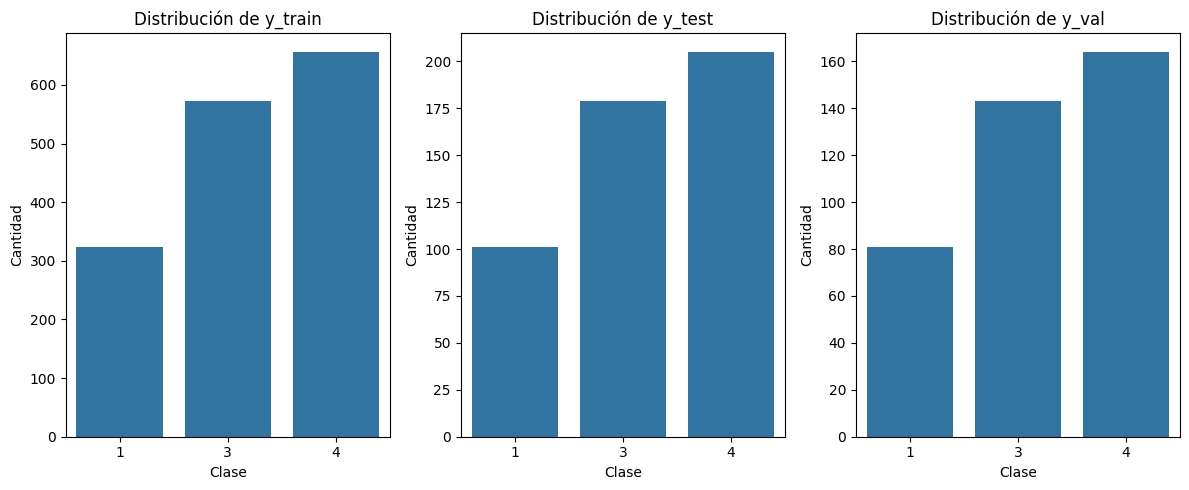

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title('Distribución de y_train')
axes[0].set_xlabel('Clase')
axes[0].set_ylabel('Cantidad')

sns.countplot(x=y_test, ax=axes[1])
axes[1].set_title('Distribución de y_test')
axes[1].set_xlabel('Clase')
axes[1].set_ylabel('Cantidad')

sns.countplot(x=y_val, ax=axes[2])
axes[2].set_title('Distribución de y_val')
axes[2].set_xlabel('Clase')
axes[2].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

In [47]:
# Vectorizador elegido: TF-IDF con 1-gramas + 2-gramas
vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    max_features=50000,   # límite para controlar dimensionalidad (cantidad de features)
    min_df=2,             # ignora tokens muy raros
    norm='l2',
    sublinear_tf=True
)

# Fit solo en train, luego transformar train/test
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf  = vectorizer.transform(X_test)
X_val_tfidf = vectorizer.transform(X_val)

print("Shapes: X_train", X_train_tfidf.shape, "X_test", X_test_tfidf.shape, "X_val", X_val_tfidf.shape)

Shapes: X_train (1551, 12785) X_test (485, 12785) X_val (388, 12785)


In [48]:
feature_names = vectorizer.get_feature_names_out()
X_train_tfidf_df = pd.DataFrame(X_train_tfidf.toarray(), columns=feature_names, index=X_train.index)
display(X_train_tfidf_df.head())

,abaj,abaj haci,abandon,abandon escol,abandon escuel,abandon estudi,abandon program,abarc,abarqu,abiert,...,xx,xxi,york,york oxford,zeland,zeland tambi,zon,zon remot,zon rural,zon urban
1640,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1379,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
681,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
695,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
741,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [49]:
X_test_tfidf_df = pd.DataFrame(X_test_tfidf.toarray(), columns=feature_names, index=X_test.index)
display(X_test_tfidf_df.head())

,abaj,abaj haci,abandon,abandon escol,abandon escuel,abandon estudi,abandon program,abarc,abarqu,abiert,...,xx,xxi,york,york oxford,zeland,zeland tambi,zon,zon remot,zon rural,zon urban
102,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.117906,0.0,0.0,0.0,0.0,0.0
1220,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
233,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
2056,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
698,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0


In [50]:
X_val_tfidf_df = pd.DataFrame(X_val_tfidf.toarray(), columns=feature_names, index=X_val.index)
display(X_val_tfidf_df.head())

,abaj,abaj haci,abandon,abandon escol,abandon escuel,abandon estudi,abandon program,abarc,abarqu,abiert,...,xx,xxi,york,york oxford,zeland,zeland tambi,zon,zon remot,zon rural,zon urban
1965,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
2108,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
1789,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
993,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
1427,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.118819,0.0,0.0,0.0,0.0,0.0


In [51]:
lowest_index = X_train_tfidf_df.index.min()
print(f"Texto {lowest_index}: {original_data['textos'].iloc[lowest_index]}")

Texto 0: "Aprendizaje" y "educación" se consideran sinónimos de escolarización formal. Las organizaciones auxiliares, como las editoriales de educación, las juntas examinadoras y las organizaciones de formación de docentes, se consideran extensiones de los acuerdos establecidos por los gobiernos. Este marco de comprensión se ha vuelto cada vez más inadecuado.


In [52]:
row_lowest_index = X_train_tfidf_df.loc[lowest_index]
nonzero_columns = row_lowest_index[row_lowest_index != 0]

print(nonzero_columns)

acuerd              0.183090
aprendizaj          0.119376
auxiliar            0.243112
cad                 0.120434
cad vez             0.178866
comprension         0.197934
consider            0.210005
docent              0.126974
editorial           0.264366
educ                0.141253
escolariz           0.222642
establec            0.139906
examin              0.179879
extension           0.248967
formacion           0.134567
formacion docent    0.216788
formal              0.187843
gobi                0.181989
inadecu             0.219603
junt                0.168443
marc                0.151071
mas                 0.066055
organiz             0.250326
vez                 0.146120
vez mas             0.186598
vuelt               0.248967
vuelt cad           0.275291
Name: 0, dtype: float64


#### **Resumen de Estructuras de Datos Resultantes**

In [53]:
print("Tipado de X's y y's por conjunto:")
print("Train (X, y):", type(X_train), type(y_train))
print("Test (X, y):", type(X_test), type(y_test))
print("Validation (X, y):", type(X_val), type(y_val))

Tipado de X's y y's por conjunto:
Train (X, y): <class 'pandas.core.series.Series'> <class 'numpy.ndarray'>
Test (X, y): <class 'pandas.core.series.Series'> <class 'numpy.ndarray'>
Validation (X, y): <class 'pandas.core.series.Series'> <class 'numpy.ndarray'>


In [54]:
print("Dimensiones de X's y y's por conjunto (train, test, val):")
print("X:", X_train.shape, X_test.shape, X_val.shape)
print("y:", y_train.shape, y_test.shape, y_val.shape)

Dimensiones de X's y y's por conjunto (train, test, val):
X: (1551,) (485,) (388,)
y: (1551,) (485,) (388,)


In [55]:
print("Verificación de cardinalidad total:")
print(X_train.shape[0] + X_test.shape[0] + X_val.shape[0] == original_data.shape[0])

Verificación de cardinalidad total:
True


Los datos preprocesados, pero sin vectorizar están en las series de pandas X_train, X_test, X_val y las etiquetas en los numpy arrays y_train, y_test, y_val.

In [56]:
df_train = X_train_tfidf_df
df_test = X_test_tfidf_df
df_val = X_val_tfidf_df

In [57]:
print(df_train.shape)
display(df_train.head())

(1551, 12785)


,abaj,abaj haci,abandon,abandon escol,abandon escuel,abandon estudi,abandon program,abarc,abarqu,abiert,...,xx,xxi,york,york oxford,zeland,zeland tambi,zon,zon remot,zon rural,zon urban
1640,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1379,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
681,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
695,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
741,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [58]:
print(df_test.shape)
display(df_test.head())

(485, 12785)


,abaj,abaj haci,abandon,abandon escol,abandon escuel,abandon estudi,abandon program,abarc,abarqu,abiert,...,xx,xxi,york,york oxford,zeland,zeland tambi,zon,zon remot,zon rural,zon urban
102,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.117906,0.0,0.0,0.0,0.0,0.0
1220,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
233,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
2056,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
698,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0


In [59]:
print(df_val.shape)
display(df_val.head())

(388, 12785)


,abaj,abaj haci,abandon,abandon escol,abandon escuel,abandon estudi,abandon program,abarc,abarqu,abiert,...,xx,xxi,york,york oxford,zeland,zeland tambi,zon,zon remot,zon rural,zon urban
1965,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
2108,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
1789,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
993,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
1427,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.118819,0.0,0.0,0.0,0.0,0.0


### **Mejor modelo de la etapa 1: Naive-Bayes**

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Mejores hiperparámetros encontrados: {'nb__alpha': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
CV f1_macro: 0.961

------------------ Métricas en test ------------------
accuracy: 0.963
balanced_acc: 0.958
f1_macro: 0.96
f1_weighted: 0.963

Reporte por clase:
               precision    recall  f1-score   support

           1      0.959     0.931     0.945       101
           3      0.956     0.978     0.967       179
           4      0.971     0.966     0.968       205

    accuracy                          0.963       485
   macro avg      0.962     0.958     0.960       485
weighted avg      0.963     0.963     0.963       485



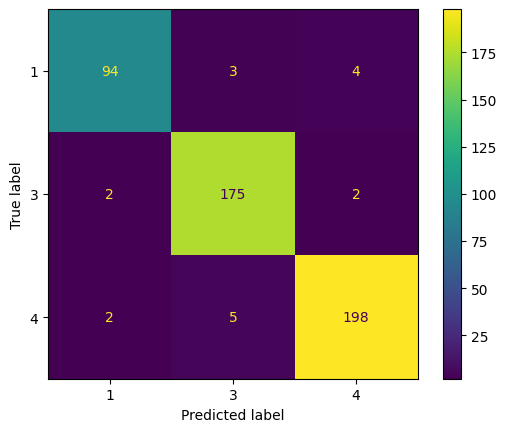

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             balanced_accuracy_score, accuracy_score)

# === Pipeline: TF-IDF -> Naive Bayes ===
pipe_nb = Pipeline(steps=[
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        strip_accents='unicode',
        ngram_range=(1,1),
        min_df=2
    )),
    ('nb', MultinomialNB())
])

# === Grid MUY corto enfocado en F1-macro ===
param_grid_nb = {
    'tfidf__ngram_range': [(1,1), (1,2)],
    'tfidf__min_df': [1, 2],
    'nb__alpha': [0.1, 0.5, 1.0],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipe_nb, param_grid_nb, scoring='f1_macro', cv=cv, n_jobs=1, verbose=1)

grid.fit(X_train, y_train)

print("Mejores hiperparámetros encontrados:", grid.best_params_)
print("CV f1_macro:", round(grid.best_score_, 3))

best_nb = grid.best_estimator_

print("\n------------------ Métricas en test ------------------")
y_pred_nb = best_nb.predict(X_test)
print("accuracy:", round(accuracy_score(y_test, y_pred_nb), 3))
print("balanced_acc:", round(balanced_accuracy_score(y_test, y_pred_nb), 3))
print("f1_macro:", round(f1_score(y_test, y_pred_nb, average='macro'), 3))
print("f1_weighted:", round(f1_score(y_test, y_pred_nb, average='weighted'), 3))
print("\nReporte por clase:\n", classification_report(y_test, y_pred_nb, digits=3))

cm = confusion_matrix(y_test, y_pred_nb, labels=best_nb.classes_)
ConfusionMatrixDisplay(cm, display_labels=best_nb.classes_).plot(xticks_rotation=0)


### **Validación del modelo con los datos nuevos etapa 2**

Primero se debe realizar el proceso de preparación. Se realizarán los mismos procedimientos usados en la primera etapa para el anterior conjunto de datos.

In [61]:
original_data = pd.read_excel('data/Datos_etapa 2.xlsx')

print("Dimensiones:", original_data.shape, "\n")

print("Tipos de datos por columna:")
print(original_data.dtypes)

display(original_data.head())

print("\nValores únicos por columna:")
print(original_data.nunique())

Dimensiones: (99, 2) 

Tipos de datos por columna:
textos    object
labels     int64
dtype: object


,textos,labels
0,La definición de privación está basada en el m...,1
1,La mayoría de los programas de protección soci...,1
2,Esto es dos veces y media mayor que la partici...,1
3,El enfoque aquí está en los aspectos de la pob...,1
4,El factor educativo representa una mayor contr...,1



Valores únicos por columna:
textos    99
labels     3
dtype: int64


In [62]:
#completitud
print("Valores nulos por columna:")
print(original_data.isnull().sum())
#unicidad
print("Cantidad de textos duplicados:")
print(original_data['textos'].duplicated().sum())
#validez
print("Conteo de valores de labels:")
print(original_data['labels'].value_counts())
original_data['textos'] = original_data['textos'].astype('string')
print("Tipos de datos por columna:")
print(original_data.dtypes)

Valores nulos por columna:
textos    0
labels    0
dtype: int64
Cantidad de textos duplicados:
0
Conteo de valores de labels:
labels
4    43
3    35
1    21
Name: count, dtype: int64
Tipos de datos por columna:
textos    string[python]
labels             int64
dtype: object


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\juanc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\juanc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Distribución original (proporciones):
1    0.212121
3    0.353535
4    0.434343
Name: proportion, dtype: float64

Tamaños (nº muestras):
Total: 99
Train: 63
Validation: 16
Test: 20

Distribuciones por conjunto (proporciones):
Train:
1    0.222222
3    0.349206
4    0.428571
Name: proportion, dtype: float64
Validation:
1    0.1875
3    0.3750
4    0.4375
Name: proportion, dtype: float64
Test:
1    0.20
3    0.35
4    0.45
Name: proportion, dtype: float64

Ejemplo (primer elemento) X_train: rubric studi thinking probabl mas enfoc habit pensamient artes visual rubric inicial ocde caract general rubric cinc habit creativ ment comun utiliz program creativ partnerships existi ciert alin rubric desviacion protocol proyect bien proyect desarroll planteari problem fidel implement estudi valid eficaci hungri red escol implement pedagogi creativ partnerships propus altern interes equip utiliz rubric general ocde rubric cinc habit creativ ment diferent proposit
Ejemplo (primer elemento) X_val: lid

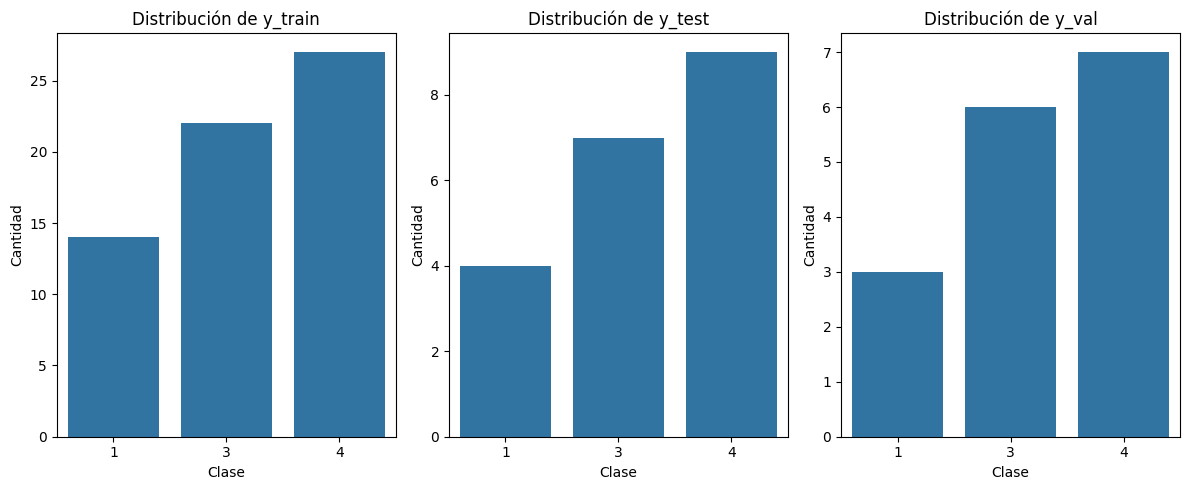

In [66]:
# Preparación

nltk.download('punkt')
nltk.download('punkt_tab')

# Funciones de reemplazo
def replace_accents(text: str) -> str:
    normalized = unicodedata.normalize('NFD', text)
    without_accents = ''.join(c for c in normalized if unicodedata.category(c) != 'Mn')
    return without_accents

def replace_numbers_with_text(text: str) -> str:
    num_map = {
        '0': 'cero',
        '1': 'uno',
        '2': 'dos',
        '3': 'tres',
        '4': 'cuatro',
        '5': 'cinco',
        '6': 'seis',
        '7': 'siete',
        '8': 'ocho',
        '9': 'nueve'
    }
    return re.sub(r'\d', lambda m: num_map[m.group()], text)

# Normalización, tokenización y stemming
stemmer = SnowballStemmer("spanish")
spanish_stopwords = set(stopwords.words("spanish"))

def basic_normalize(text: str) -> str:
    """lowercase, reemplazar acentos, reemplazar números, eliminar caracteres especiales"""
    if text is None:
        return ""
    text = str(text).lower().strip()
    text = replace_accents(text)
    text = replace_numbers_with_text(text)
    # dejar solo letras a-z y espacios
    text = re.sub(r'[^a-z\s]', ' ', text, flags=re.UNICODE)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokenize_text(text: str) -> list[str]:
    """Tokenizar usando word_tokenize (nltk.tokenize)"""
    if not text:
        return []
    return word_tokenize(text, language='spanish')

def stem_tokens(tokens: list[str], remove_sw: bool = True) -> list[str]:
    """Aplica SnowballStemmer a la lista de tokens. Opcionalmente quita stopwords."""
    if remove_sw:
        tokens = [t for t in tokens if t not in spanish_stopwords]
    return [stemmer.stem(t) for t in tokens if t.strip()]

def process_text_once(text: str, remove_stopwords: bool = True) -> str:
    """Pipeline por texto: normalize -> tokenize -> optional remove stopwords -> stem -> join."""
    basic = basic_normalize(text)
    toks = tokenize_text(basic)
    stems = stem_tokens(toks, remove_sw=remove_stopwords)
    return " ".join(stems)

def normalize_texts_nltk(series: pd.Series, remove_stopwords: bool = False) -> pd.Series:
    """Aplica process_text_once a una pd.Series de textos."""
    series = series.fillna("").astype(str)
    return series.apply(lambda s: process_text_once(s, remove_stopwords=remove_stopwords))

# Se crea una copia del DataFrame original para no modificarlo
df = original_data.copy()

# Preprocesamiento de textos
df['text_processed'] = normalize_texts_nltk(df['textos'], remove_stopwords=True)

X = df['text_processed']
y = df['labels']

# copia de x antes de hacer split
X_full = X.copy()

#copia de y antes de hacer split
y_full = y.copy()

TEST_SIZE = 0.20    # porcentaje final para test
VAL_SIZE = 0.16     # porcentaje final para validation
RANDOM_STATE = 42

# Series de entrada
X = df['text_processed'].astype(str)
y = df['labels'].values

# Proporciones originales de las clases
print("Distribución original (proporciones):")
print(pd.Series(y).value_counts(normalize=True).sort_index())

# 1) Primer split: sacar TEST (manteniendo stratify si es posible)
try:
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
    )
except ValueError as e:
    print("WARNING: stratify falló en la separación test (posible clase con muy pocas muestras).")
    print("Detalle:", e)
    print("Procediendo con split no estratificado para test.")
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=None
    )

# 2) Segundo split: dividir X_temp en TRAIN y VALIDATION
# Queremos que validation tenga VAL_SIZE de todo el dataset.
# Dado que X_temp tiene (1 - TEST_SIZE) del total, la fracción relativa es:
val_relative = VAL_SIZE / (1.0 - TEST_SIZE)
if not (0.0 < val_relative < 1.0):
    raise ValueError(f"VAL_SIZE ({VAL_SIZE}) incompatible con TEST_SIZE ({TEST_SIZE}).")

try:
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_relative, random_state=RANDOM_STATE, stratify=y_temp
    )
except ValueError as e:
    print("WARNING: stratify falló en la separación train/validation (posible clase con pocas muestras).")
    print("Detalle:", e)
    print("Procediendo con split no estratificado para validation.")
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_relative, random_state=RANDOM_STATE, stratify=None
    )

# Resumen de tamaños y proporciones
print("\nTamaños (nº muestras):")
print("Total:", len(X))
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nDistribuciones por conjunto (proporciones):")
print("Train:")
print(pd.Series(y_train).value_counts(normalize=True).sort_index())
print("Validation:")
print(pd.Series(y_val).value_counts(normalize=True).sort_index())
print("Test:")
print(pd.Series(y_test).value_counts(normalize=True).sort_index())

# Ejemplo de acceso
print("\nEjemplo (primer elemento) X_train:", X_train.iloc[0])
print("Ejemplo (primer elemento) X_val:", X_val.iloc[0])
print("Ejemplo (primer elemento) X_test:", X_test.iloc[0])


# Proporciones por conjunto

fig, axes = plt.subplots(1, 3, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title('Distribución de y_train')
axes[0].set_xlabel('Clase')
axes[0].set_ylabel('Cantidad')

sns.countplot(x=y_test, ax=axes[1])
axes[1].set_title('Distribución de y_test')
axes[1].set_xlabel('Clase')
axes[1].set_ylabel('Cantidad')

sns.countplot(x=y_val, ax=axes[2])
axes[2].set_title('Distribución de y_val')
axes[2].set_xlabel('Clase')
axes[2].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()


In [64]:
# Vectorización TF-IDF

# Vectorizador elegido: TF-IDF con 1-gramas + 2-gramas
vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    max_features=50000,   # límite para controlar dimensionalidad (cantidad de features)
    min_df=2,             # ignora tokens muy raros
    norm='l2',
    sublinear_tf=True
)

# Fit solo en train, luego transformar train/test
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf  = vectorizer.transform(X_test)
X_val_tfidf = vectorizer.transform(X_val)

print("Shapes: X_train", X_train_tfidf.shape, "X_test", X_test_tfidf.shape, "X_val", X_val_tfidf.shape)

feature_names = vectorizer.get_feature_names_out()
X_train_tfidf_df = pd.DataFrame(X_train_tfidf.toarray(), columns=feature_names, index=X_train.index)
display(X_train_tfidf_df.head())

X_test_tfidf_df = pd.DataFrame(X_test_tfidf.toarray(), columns=feature_names, index=X_test.index)
display(X_test_tfidf_df.head())

X_val_tfidf_df = pd.DataFrame(X_val_tfidf.toarray(), columns=feature_names, index=X_val.index)
display(X_val_tfidf_df.head())

Shapes: X_train (63, 716) X_test (20, 716) X_val (16, 716)


,abandon,abandon escol,abord,abord problem,academ,acces,activ,activ apoy,actor,actual,...,virtual,vision,vision mas,visit,viviend,viviend emple,volumen,volumen dat,vulner,zon
73,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.00000,0.0,0.0,0.000000,0.0
8,0.0,0.0,0.0,0.0,0.186246,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.197955,0.21305,0.0,0.0,0.000000,0.0
31,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.146932,0.000000,0.00000,0.0,0.0,0.000000,0.0
43,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.00000,0.0,0.0,0.109034,0.0
77,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.00000,0.0,0.0,0.000000,0.0


,abandon,abandon escol,abord,abord problem,academ,acces,activ,activ apoy,actor,actual,...,virtual,vision,vision mas,visit,viviend,viviend emple,volumen,volumen dat,vulner,zon
57,0.0,0.0,0.0,0.0,0.0,0.0,0.204058,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
72,0.0,0.0,0.0,0.0,0.0,0.0,0.199971,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
22,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
90,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42,0.0,0.0,0.0,0.0,0.0,0.0,0.238928,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,abandon,abandon escol,abord,abord problem,academ,acces,activ,activ apoy,actor,actual,...,virtual,vision,vision mas,visit,viviend,viviend emple,volumen,volumen dat,vulner,zon
65,0.178918,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
64,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
71,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.213857,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
38,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
55,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [65]:
# Resumen de estructuras de datos

print("Tipado de X's y y's por conjunto:")
print("Train (X, y):", type(X_train), type(y_train))
print("Test (X, y):", type(X_test), type(y_test))
print("Validation (X, y):", type(X_val), type(y_val))

print("Dimensiones de X's y y's por conjunto (train, test, val):")
print("X:", X_train.shape, X_test.shape, X_val.shape)
print("y:", y_train.shape, y_test.shape, y_val.shape)

print("Verificación de cardinalidad total:")
print(X_train.shape[0] + X_test.shape[0] + X_val.shape[0] == original_data.shape[0])

df_train = X_train_tfidf_df
df_test = X_test_tfidf_df
df_val = X_val_tfidf_df

Tipado de X's y y's por conjunto:
Train (X, y): <class 'pandas.core.series.Series'> <class 'numpy.ndarray'>
Test (X, y): <class 'pandas.core.series.Series'> <class 'numpy.ndarray'>
Validation (X, y): <class 'pandas.core.series.Series'> <class 'numpy.ndarray'>
Dimensiones de X's y y's por conjunto (train, test, val):
X: (63,) (20,) (16,)
y: (63,) (20,) (16,)
Verificación de cardinalidad total:
True


### **Validación de métricas en el mejor modelo con datos nuevos (sin técnicas de prompting)**


------------------ Métricas en test ------------------
accuracy: 0.909
balanced_acc: 0.89
f1_macro: 0.901
f1_weighted: 0.908

Reporte por clase:
               precision    recall  f1-score   support

           1      1.000     0.762     0.865        21
           3      0.854     1.000     0.921        35
           4      0.929     0.907     0.918        43

    accuracy                          0.909        99
   macro avg      0.927     0.890     0.901        99
weighted avg      0.917     0.909     0.908        99



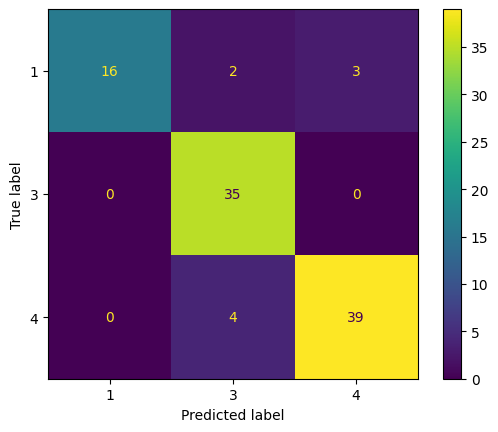

In [68]:
from sklearn.metrics import (
    classification_report, accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_model = best_nb

print("\n------------------ Métricas en test ------------------")
y_pred_nb = best_model.predict(X_full)
print("accuracy:", round(accuracy_score(y_full, y_pred_nb), 3))
print("balanced_acc:", round(balanced_accuracy_score(y_full, y_pred_nb), 3))
print("f1_macro:", round(f1_score(y_full, y_pred_nb, average='macro'), 3))
print("f1_weighted:", round(f1_score(y_full, y_pred_nb, average='weighted'), 3))
print("\nReporte por clase:\n", classification_report(y_full, y_pred_nb, digits=3))

cm = confusion_matrix(y_full, y_pred_nb, labels=best_model.classes_)
ConfusionMatrixDisplay(cm, display_labels=best_model.classes_).plot(xticks_rotation=0)

### Reentrenar mejor modelo con técnicas de prompting

Distribución y_train:
 4    27
3    22
1    14
Name: count, dtype: int64 
Minoritaria: 1 Mayorit.: 4
Objetivo de balanceo: generar 13 textos para la clase 1.
Sintéticos generados (tras filtros): 13
Tamaño train original: 63  | aumentado: 76
Distribución original:
 4    27
3    22
1    14
Name: count, dtype: int64
Distribución aumentada:
 4    27
1    27
3    22
Name: count, dtype: int64

--- ANTES de augmentación – VALIDACIÓN ---
accuracy   : 0.875
bal_acc    : 0.841
f1_macro   : 0.860
f1_weighted: 0.875

Reporte por clase:
               precision    recall  f1-score   support

           1      1.000     0.667     0.800         3
           3      0.750     1.000     0.857         6
           4      1.000     0.857     0.923         7

    accuracy                          0.875        16
   macro avg      0.917     0.841     0.860        16
weighted avg      0.906     0.875     0.875        16



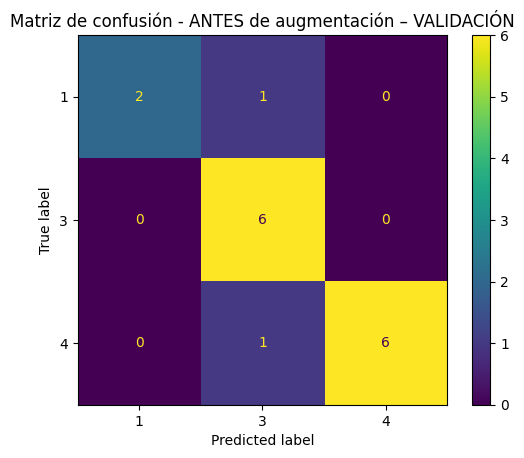


--- DESPUÉS de augmentación – VALIDACIÓN ---
accuracy   : 0.812
bal_acc    : 0.833
f1_macro   : 0.800
f1_weighted: 0.794

Reporte por clase:
               precision    recall  f1-score   support

           1      0.750     1.000     0.857         3
           3      1.000     0.500     0.667         6
           4      0.778     1.000     0.875         7

    accuracy                          0.812        16
   macro avg      0.843     0.833     0.800        16
weighted avg      0.856     0.812     0.794        16



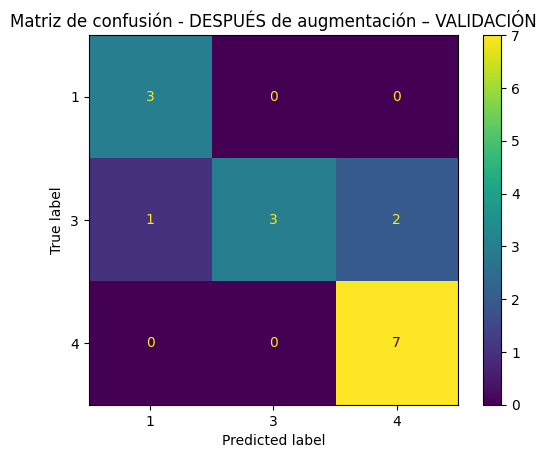

In [ ]:
# ============================
# 1) Imports y cliente OpenAI
# ============================
import os, json, math, re, random
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (classification_report, accuracy_score,
                             balanced_accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

from openai import OpenAI
# Asegúrate de tener la API key en el entorno
os.environ["OPENAI_API_KEY"] = ""  # <- opcional si no la tienes como variable de entorno
client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))

# Utilidad: garantizar que X sea Serie de str y y sea Serie
def _as_series(x):
    s = pd.Series(x)
    s = s.fillna("").astype(str).reset_index(drop=True)
    return s

X_train_s = _as_series(X_train)
y_train_s = pd.Series(y_train)

# ============================
# 2) Detección de clase minoritaria
# ============================
vc = y_train_s.value_counts()
minor_label = vc.idxmin()
major_label = vc.idxmax()
print("Distribución y_train:\n", vc, "\nMinoritaria:", minor_label, "Mayorit.:", major_label)

# ============================
# 3) Función de llamada LLM (JSON mode)
# ============================
def llm_json(prompt: str, model: str = "gpt-4o-mini",
             temperature: float = 0.4, max_tokens: int = 1200) -> dict:
    """
    Llama al modelo y devuelve un dict (JSON). Intenta primero con response_format,
    y si tu SDK no lo soporta, cae a una llamada normal y parsea el JSON del texto.
    """
    sys = (
        "Eres un generador de datos sintéticos en ESPAÑOL para un clasificador de ODS. "
        "Devuelve EXCLUSIVAMENTE un JSON válido (sin texto adicional)."
    )
    # 1) Intento con response_format (si tu SDK lo soporta)
    try:
        resp = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": sys},
                {"role": "user", "content": prompt},
            ],
            temperature=temperature,
            max_tokens=max_tokens,
            response_format={"type": "json_object"},
        )
        text = resp.choices[0].message.content
    except TypeError:
        # 2) Fallback sin response_format
        resp = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": sys},
                {"role": "user", "content": prompt},
            ],
            temperature=temperature,
            max_tokens=max_tokens,
        )
        text = resp.choices[0].message.content

    # 3) Parseo robusto a dict
    try:
        return json.loads(text)
    except Exception:
        m = re.search(r"\{.*\}", text, flags=re.S)
        if m:
            try:
                return json.loads(m.group(0))
            except Exception:
                pass
        # Último recurso: convierte líneas a samples
        items = [ln.strip("-• \n\r\t") for ln in text.splitlines() if ln.strip()]
        return {"synthetic_samples": [{"texto": it} for it in items]}

# ============================
# 4) Construcción del prompt few-shot
# ============================
def construir_prompt(ejemplos:list, etiqueta_minoritaria, n_solicitados:int, otras_etiquetas:list):
    """
    ejemplos: lista de textos reales de la clase minoritaria (limpios).
    otras_etiquetas: etiquetas distintas a la minoritaria para evitar “contaminación semántica”.
    """
    # Limita a 10-12 ejemplos para que sea compacto
    ejemplos = ejemplos[:12]
    fewshot = [{"texto": t} for t in ejemplos]

    instrucciones = f"""
Eres un generador de textos sintéticos en ESPAÑOL para un clasificador de opiniones asociado a ODS.
Tu tarea: crear ejemplos REALISTAS de la clase {etiqueta_minoritaria} (minoritaria) que sean verosímiles,
variados y no copien literalmente los ejemplos de referencia.

Requisitos:
- Idioma: español natural y conciso (una o dos oraciones).
- Longitud: 12 a 50 palabras por ejemplo.
- Estilo: propio de la clase {etiqueta_minoritaria}. Evita términos característicos de clases {otras_etiquetas}.
- Variedad: usa sinónimos, ligeras variaciones de tono, y ocasionales faltas menores (realismo), sin caer en spam.
- Neutralidad de formato: texto plano, sin comillas de apertura/cierre.

Devuélveme EXCLUSIVAMENTE un objeto JSON con esta forma:
{{
  "synthetic_samples": [
      {{ "texto": "..." }},
      ...
  ]
}}
Dónde "synthetic_samples" contiene EXACTAMENTE {n_solicitados} ejemplos nuevos.
"""

    prompt = {
        "instrucciones": instrucciones,
        "ejemplos_reales_clase_minoritaria": fewshot
    }
    return json.dumps(prompt, ensure_ascii=False)

# ============================
# 5) Generación en lotes + filtros
# ============================
def normaliza_texto(t: str) -> str:
    t = t.strip()
    t = re.sub(r"\s+", " ", t)
    return t

def sintetizar_para_label(X_series, y_series, label, n_objetivo=300, batch=50):
    """
    Genera ~n_objetivo ejemplos de la clase 'label' en lotes 'batch'.
    Devuelve lista de textos sintéticos (filtrados y deduplicados).
    """
    # Semillas few-shot: toma ejemplos reales de esa clase
    # --- Semillas few-shot: toma ejemplos reales de esa clase (indexación POSICIONAL) ---
    X_series = _as_series(X_series).reset_index(drop=True)
    y_series = pd.Series(y_series).reset_index(drop=True)

    mask = (y_series.values == label)  # numpy bool array → fuerza alineación posicional
    n_disp = int(mask.sum())
    if n_disp == 0:
        raise ValueError(f"No hay ejemplos de la clase '{label}' en y_series.")

    n_sample = min(60, n_disp)
    ejemplos_reales = X_series[mask].sample(n_sample, random_state=42).tolist()

    otras = sorted([str(l) for l in y_series.unique() if l != label])

    sinteticos = []
    pendientes = n_objetivo
    while pendientes > 0:
        n_solic = min(batch, pendientes)

        prompt = construir_prompt(
            ejemplos=[normaliza_texto(x) for x in ejemplos_reales],
            etiqueta_minoritaria=label,
            n_solicitados=n_solic,
            otras_etiquetas=otras
        )
        try:
            data = llm_json(prompt, model="gpt-4o-mini", temperature=0.35, max_tokens=2000)
            nuevos = [normaliza_texto(d.get("texto","")) for d in data.get("synthetic_samples", [])]
        except Exception as e:
            print("⚠️  LLM error, salto de lote:", e)
            nuevos = []

        # Filtros básicos
        nuevos = [t for t in nuevos if 10 <= len(t.split()) <= 60]
        nuevos = [t for t in nuevos if len(t) >= 25]
        nuevos = [t for t in nuevos if t]

        sinteticos.extend(nuevos)
        pendientes -= n_solic

    # Deduplicación con el train real y dentro de los sintéticos
    set_train = set([normaliza_texto(t).lower() for t in X_series.tolist()])
    out = []
    seen = set()
    for t in sinteticos:
        key = t.lower()
        if key in seen: 
            continue
        if key in set_train:
            continue
        seen.add(key)
        out.append(t)

    print(f"Sintéticos generados (tras filtros): {len(out)}")
    return out

# ============================
# 6) Estrategia: balancear hasta la mayoritaria
# ============================
minor_count = vc.loc[minor_label]
major_count = vc.loc[major_label]
to_generate = max(0, major_count - minor_count)
print(f"Objetivo de balanceo: generar {to_generate} textos para la clase {minor_label}.")

if to_generate > 0:
    synth_texts = sintetizar_para_label(X_train_s, y_train_s, minor_label, n_objetivo=to_generate, batch=40)
else:
    synth_texts = []

# Si generó “de más” por filtros flojos, recorta
synth_texts = synth_texts[:to_generate]

# ============================
# 7) Conjunto aumentado y reentrenamiento
# ============================
X_aug = pd.concat([X_train_s, pd.Series(synth_texts)], ignore_index=True)
y_aug = pd.concat([y_train_s, pd.Series([minor_label]*len(synth_texts))], ignore_index=True)

print("Tamaño train original:", len(X_train_s), " | aumentado:", len(X_aug))
print("Distribución original:\n", y_train_s.value_counts())
print("Distribución aumentada:\n", y_aug.value_counts())

# Clonamos y re-entrenamos Naive Bayes (pipeline)
best_nb_aug = clone(best_nb)
best_nb_aug.fit(X_aug, y_aug)

# ============================
# 8) Evaluación antes vs después
# ============================
def eval_model(model, X_eval, y_eval, titulo="Evaluación"):
    X_eval_s = _as_series(X_eval)
    y_pred = model.predict(X_eval_s)
    acc  = accuracy_score(y_eval, y_pred)
    bacc = balanced_accuracy_score(y_eval, y_pred)
    f1m  = f1_score(y_eval, y_pred, average="macro")
    f1w  = f1_score(y_eval, y_pred, average="weighted")
    print(f"\n--- {titulo} ---")
    print(f"accuracy   : {acc:.3f}")
    print(f"bal_acc    : {bacc:.3f}")
    print(f"f1_macro   : {f1m:.3f}")
    print(f"f1_weighted: {f1w:.3f}")
    print("\nReporte por clase:\n", classification_report(y_eval, y_pred, digits=3))

    cm = confusion_matrix(y_eval, y_pred, labels=np.sort(pd.Series(y_eval).unique()))
    disp = ConfusionMatrixDisplay(cm, display_labels=np.sort(pd.Series(y_eval).unique()))
    disp.plot(values_format="d", cmap="viridis")
    plt.title(f"Matriz de confusión - {titulo}")
    plt.show()
    return {"acc":acc,"bacc":bacc,"f1_macro":f1m,"f1_weighted":f1w}

# Detecta automáticamente qué holdout tienes disponible
if "X_val" in globals() and "y_val" in globals():
    X_eval, y_eval, split_name = X_val, y_val, "VALIDACIÓN"
elif "X_test" in globals() and "y_test" in globals():
    X_eval, y_eval, split_name = X_test, y_test, "TEST"
elif "X_full" in globals() and "y_full" in globals():
    X_eval, y_eval, split_name = X_full, y_full, "CONJUNTO ETAPA 2"
else:
    raise RuntimeError("No encontré conjunto de evaluación (X_val/y_val o X_test/y_test o X_full/y_full).")

# Antes (modelo original)
_ = eval_model(best_nb, X_eval, y_eval, titulo=f"ANTES de augmentación – {split_name}")
# Después (modelo reentrenado)
_ = eval_model(best_nb_aug, X_eval, y_eval, titulo=f"DESPUÉS de augmentación – {split_name}")
